In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("final_full_datasetandronew.csv")

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
df.head()

Molecule ChEMBL ID  \
0      CHEMBL3955013   
1      CHEMBL3912767   
2      CHEMBL4104046   
3       CHEMBL445429   
4       CHEMBL510145   

                                                                               Smiles  \
0            CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1  CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                     Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                               COc1cc(SC(C)C)ccc1C#N   
4                                                          COc1cc(Sc2ccccc2OC)ccc1C#N   

   pChEMBL Value Active compound  \
0           6.48          Active   
1           6.60          Active   
2           7.17          Active   
3           8.00          Active   
4           7.70          Active   

                                                                     canonical_smiles  \
0            CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1  CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                     Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                               COc1cc(SC(C)C)ccc1C#N   
4                                                          COc1cc(Sc2ccccc2OC)ccc1C#N   

     MolWt     LogP  H_Donors  H_Acceptors    TPSA  NumRotatableBonds  \
0  541.530  5.46738       2.0          5.0  102.46                4.0   
1  643.663  5.49058       2.0          6.0  118.67               10.0   
2  241.225  2.28016       1.0          3.0   72.74                1.0   
3  207.298  3.06738       0.0          3.0   33.02                3.0   
4  271.341  3.72668       0.0          4.0   42.25                4.0   

   NumAtoms  HeavyAtomCount  NumHeteroatoms  NumCarbons  NumNitrogens  \
0      38.0            38.0            12.0        26.0           5.0   
1      45.0            45.0            14.0        31.0           5.0   
2      18.0            18.0             5.0        13.0           3.0   
3      14.0            14.0             3.0        11.0           1.0   
4      19.0            19.0             4.0        15.0           1.0   

   NumOxygens  NumHalogens  NumBonds  NumDoubleBonds  NumTripleBonds  \
0         2.0          4.0      41.0             3.0             1.0   
1         4.0          4.0      48.0             4.0             1.0   
2         1.0          1.0      19.0             0.0             2.0   
3         1.0          0.0      14.0             0.0             1.0   
4         2.0          0.0      20.0             0.0             1.0   

   NumRings  NumAromaticRings  NumAliphaticRings  NumSaturatedRings  \
0       4.0               3.0                1.0                1.0   
1       4.0               3.0                1.0                1.0   
2       2.0               2.0                0.0                0.0   
3       1.0               1.0                0.0                0.0   
4       2.0               2.0                0.0                0.0   

   NumAromaticAtoms  NumAliphaticAtoms  FractionCSP3  morgan_0  morgan_1  \
0              18.0               20.0      0.153846         0         0   
1              18.0               27.0      0.322581         0         0   
2              11.0                7.0      0.076923         0         0   
3               6.0                8.0      0.363636         0         1   
4              12.0                7.0      0.133333         0         0   

   morgan_2  morgan_3  morgan_4  morgan_5  morgan_6  morgan_7  morgan_8  \
0         0         0         0         0         0         0         0   
1         0         0         0         0         0         0         1   
2         0         0         0         0         0         0         0   
3         0         0         0         0         0         0         0   


In [4]:
df.info()   # Dataset Info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2309 entries, 0 to 2308
Columns: 5148 entries, Molecule ChEMBL ID to rdk_2047
dtypes: float64(24), int64(5120), object(4)
memory usage: 90.7+ MB


In [5]:
df.shape   # No. of Features and Datapoints

(2309, 5148)

In [6]:
df = df[[c for c in df.columns if (
    'morgan' in c.lower() 
    or not any(fp in c.lower() for fp in ['rdk', 'atompair', 'maccs', 'pubchem'])
)]]

In [7]:
df

Molecule ChEMBL ID  \
0         CHEMBL3955013   
1         CHEMBL3912767   
2         CHEMBL4104046   
3          CHEMBL445429   
4          CHEMBL510145   
...                 ...   
2304      CHEMBL6148700   
2305      CHEMBL6164251   
2306      CHEMBL6162640   
2307      CHEMBL6152535   
2308      CHEMBL6171040   

                                                                                  Smiles  \
0               CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1     CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                        Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                                  COc1cc(SC(C)C)ccc1C#N   
4                                                             COc1cc(Sc2ccccc2OC)ccc1C#N   
...                                                                                  ...   
2304                                   COc1cccc(-c2cc(C(=O)Nc3nc(CN4CCOCC4)ns3)c(C)o2)c1   
2305                                            O=c1cc(C(F)(F)F)c2ccc(NCc3ccccc3Br)cc2o1   
2306                                          O=c1cc(C(F)(F)F)c2ccc(NCc3cccc(Br)c3)cc2o1   
2307                                         N#Cc1ccc(CNc2ccc3c(C(F)(F)F)cc(=O)oc3c2)cc1   
2308                                           O=c1cc(C(F)(F)F)c2ccc(NCc3ccc(F)cc3)cc2o1   

      pChEMBL Value Active compound  \
0              6.48          Active   
1              6.60          Active   
2              7.17          Active   
3              8.00          Active   
4              7.70          Active   
...             ...             ...   
2304           7.66          Active   
2305           7.00          Active   
2306           6.96          Active   
2307           6.05          Active   
2308           7.62          Active   

                                                                        canonical_smiles  \
0               CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1     CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                        Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                                  COc1cc(SC(C)C)ccc1C#N   
4                                                             COc1cc(Sc2ccccc2OC)ccc1C#N   
...                                                                                  ...   
2304                                   COc1cccc(-c2cc(C(=O)Nc3nc(CN4CCOCC4)ns3)c(C)o2)c1   
2305                                            O=c1cc(C(F)(F)F)c2ccc(NCc3ccccc3Br)cc2o1   
2306                                          O=c1cc(C(F)(F)F)c2ccc(NCc3cccc(Br)c3)cc2o1   
2307                                         N#Cc1ccc(CNc2ccc3c(C(F)(F)F)cc(=O)oc3c2)cc1   
2308                                           O=c1cc(C(F)(F)F)c2ccc(NCc3ccc(F)cc3)cc2o1   

        MolWt     LogP  H_Donors  H_Acceptors    TPSA  NumRotatableBonds  \
0     541.530  5.46738       2.0          5.0  102.46                4.0   
1     643.663  5.49058       2.0          6.0  118.67               10.0   
2     241.225  2.28016       1.0          3.0   72.74                1.0   
3     207.298  3.06738       0.0          3.0   33.02                3.0   
4     271.341  3.72668       0.0          4.0   42.25                4.0   
...       ...      ...       ...          ...     ...                ...   
2304  414.487  3.19962       1.0          8.0   89.72                6.0   
2305  398.178  5.18640       1.0          3.0   42.24                3.0   
2306  398.178  5.18640       1.0          3.0   42.24                3.0   
2307  344.292  4.29558       1.0          4.0   66.03                3.0   
2308  337.272  4.56300       1.0          3.0   42.24                3.0   

      NumAtoms  HeavyAtomCount  NumHeteroatoms  NumCarbons  NumNitrogens  \
0         38

# eliminating zeros

In [8]:
# Calculate sum of numeric features only
feature_sum = df.sum(numeric_only=True)

# Find features with sum = 0
zero_features = feature_sum[feature_sum == 0].index

# Remove those features
df = df.drop(columns=zero_features)

print("Removed columnsandronew:", len(zero_features))

Removed columnsandronew: 46


In [9]:
df

Molecule ChEMBL ID  \
0         CHEMBL3955013   
1         CHEMBL3912767   
2         CHEMBL4104046   
3          CHEMBL445429   
4          CHEMBL510145   
...                 ...   
2304      CHEMBL6148700   
2305      CHEMBL6164251   
2306      CHEMBL6162640   
2307      CHEMBL6152535   
2308      CHEMBL6171040   

                                                                                  Smiles  \
0               CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1     CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                        Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                                  COc1cc(SC(C)C)ccc1C#N   
4                                                             COc1cc(Sc2ccccc2OC)ccc1C#N   
...                                                                                  ...   
2304                                   COc1cccc(-c2cc(C(=O)Nc3nc(CN4CCOCC4)ns3)c(C)o2)c1   
2305                                            O=c1cc(C(F)(F)F)c2ccc(NCc3ccccc3Br)cc2o1   
2306                                          O=c1cc(C(F)(F)F)c2ccc(NCc3cccc(Br)c3)cc2o1   
2307                                         N#Cc1ccc(CNc2ccc3c(C(F)(F)F)cc(=O)oc3c2)cc1   
2308                                           O=c1cc(C(F)(F)F)c2ccc(NCc3ccc(F)cc3)cc2o1   

      pChEMBL Value Active compound  \
0              6.48          Active   
1              6.60          Active   
2              7.17          Active   
3              8.00          Active   
4              7.70          Active   
...             ...             ...   
2304           7.66          Active   
2305           7.00          Active   
2306           6.96          Active   
2307           6.05          Active   
2308           7.62          Active   

                                                                        canonical_smiles  \
0               CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1     CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                        Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                                  COc1cc(SC(C)C)ccc1C#N   
4                                                             COc1cc(Sc2ccccc2OC)ccc1C#N   
...                                                                                  ...   
2304                                   COc1cccc(-c2cc(C(=O)Nc3nc(CN4CCOCC4)ns3)c(C)o2)c1   
2305                                            O=c1cc(C(F)(F)F)c2ccc(NCc3ccccc3Br)cc2o1   
2306                                          O=c1cc(C(F)(F)F)c2ccc(NCc3cccc(Br)c3)cc2o1   
2307                                         N#Cc1ccc(CNc2ccc3c(C(F)(F)F)cc(=O)oc3c2)cc1   
2308                                           O=c1cc(C(F)(F)F)c2ccc(NCc3ccc(F)cc3)cc2o1   

        MolWt     LogP  H_Donors  H_Acceptors    TPSA  NumRotatableBonds  \
0     541.530  5.46738       2.0          5.0  102.46                4.0   
1     643.663  5.49058       2.0          6.0  118.67               10.0   
2     241.225  2.28016       1.0          3.0   72.74                1.0   
3     207.298  3.06738       0.0          3.0   33.02                3.0   
4     271.341  3.72668       0.0          4.0   42.25                4.0   
...       ...      ...       ...          ...     ...                ...   
2304  414.487  3.19962       1.0          8.0   89.72                6.0   
2305  398.178  5.18640       1.0          3.0   42.24                3.0   
2306  398.178  5.18640       1.0          3.0   42.24                3.0   
2307  344.292  4.29558       1.0          4.0   66.03                3.0   
2308  337.272  4.56300       1.0          3.0   42.24                3.0   

      NumAtoms  HeavyAtomCount  NumHeteroatoms  NumCarbons  NumNitrogens  \
0         38

# missing values

In [10]:
df.isnull().sum()

Molecule ChEMBL ID    0
Smiles                0
pChEMBL Value         0
Active compound       0
canonical_smiles      0
                     ..
morgan_2043           0
morgan_2044           0
morgan_2045           0
morgan_2046           0
morgan_2047           0
Length: 2030, dtype: int64

In [11]:
print(df.shape)

(2309, 2030)


In [12]:
df = df.drop_duplicates(subset = ['Molecule ChEMBL ID', 'canonical_smiles'])

In [13]:
df.drop(['Molecule ChEMBL ID', 'canonical_smiles'], axis = 1, inplace = True)

In [14]:
df

Smiles  \
0               CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
1     CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)NCCCCCCn2cccc(O)c2=O)c(F)c1   
2                                                        Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                                  COc1cc(SC(C)C)ccc1C#N   
4                                                             COc1cc(Sc2ccccc2OC)ccc1C#N   
...                                                                                  ...   
2304                                   COc1cccc(-c2cc(C(=O)Nc3nc(CN4CCOCC4)ns3)c(C)o2)c1   
2305                                            O=c1cc(C(F)(F)F)c2ccc(NCc3ccccc3Br)cc2o1   
2306                                          O=c1cc(C(F)(F)F)c2ccc(NCc3cccc(Br)c3)cc2o1   
2307                                         N#Cc1ccc(CNc2ccc3c(C(F)(F)F)cc(=O)oc3c2)cc1   
2308                                           O=c1cc(C(F)(F)F)c2ccc(NCc3ccc(F)cc3)cc2o1   

      pChEMBL Value Active compound    MolWt     LogP  H_Donors  H_Acceptors  \
0              6.48          Active  541.530  5.46738       2.0          5.0   
1              6.60          Active  643.663  5.49058       2.0          6.0   
2              7.17          Active  241.225  2.28016       1.0          3.0   
3              8.00          Active  207.298  3.06738       0.0          3.0   
4              7.70          Active  271.341  3.72668       0.0          4.0   
...             ...             ...      ...      ...       ...          ...   
2304           7.66          Active  414.487  3.19962       1.0          8.0   
2305           7.00          Active  398.178  5.18640       1.0          3.0   
2306           6.96          Active  398.178  5.18640       1.0          3.0   
2307           6.05          Active  344.292  4.29558       1.0          4.0   
2308           7.62          Active  337.272  4.56300       1.0          3.0   

        TPSA  NumRotatableBonds  NumAtoms  HeavyAtomCount  NumHeteroatoms  \
0     102.46                4.0      38.0            38.0            12.0   
1     118.67               10.0      45.0            45.0            14.0   
2      72.74                1.0      18.0            18.0             5.0   
3      33.02                3.0      14.0            14.0             3.0   
4      42.25                4.0      19.0            19.0             4.0   
...      ...                ...       ...             ...             ...   
2304   89.72                6.0      29.0            29.0             9.0   
2305   42.24                3.0      24.0            24.0             7.0   
2306   42.24                3.0      24.0            24.0             7.0   
2307   66.03                3.0      25.0            25.0             7.0   
2308   42.24                3.0      24.0            24.0             7.0   

      NumCarbons  NumNitrogens  NumOxygens  NumHalogens  NumBonds  \
0           26.0           5.0         2.0          4.0      41.0   
1           31.0           5.0         4.0          4.0      48.0   
2           13.0           3.0         1.0          1.0      19.0   
3           11.0           1.0         1.0          0.0      14.0   
4           15.0           1.0         2.0          0.0      20.0   
...          ...           ...         ...          ...       ...   
2304        20.0           4.0         4.0          0.0      32.0   
2305        17.0           1.0         2.0          4.0      26.0   
2306        17.0           1.0         2.0          4.0      26.0   
2307        18.0           2.0         2.0          3.0      27.0   
2308        17.0           1.0         2.0          4.0      26.0   

      NumDoubleBonds  NumTripleBonds  NumRings  NumAromaticRings  \
0                3.0             1.0       4.0               3.0   
1                4.0             1.0       4.0               3.0   
2                0.0             2.0       2.0            

# label encoding 

In [15]:
from sklearn.preprocessing import LabelEncoder

In [16]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["Active compound"] = le.fit_transform(df["Active compound"])

In [17]:
df['Active compound'].value_counts()

Active compound
0    2196
1     113
Name: count, dtype: int64

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

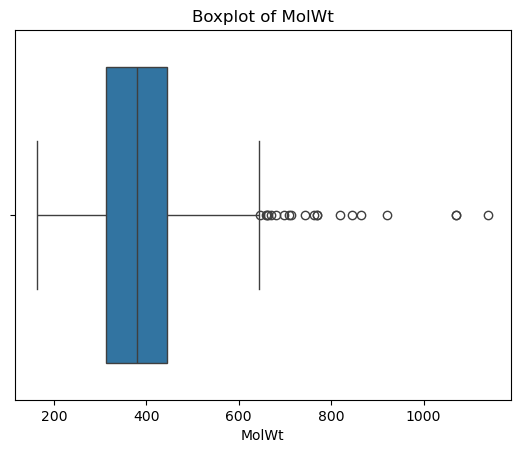

In [19]:
sns.boxplot (x =df ['MolWt'])
plt.title ("Boxplot of MolWt")
plt.show()

In [20]:
numeric_cols = ["MolWt", "LogP", "H_Acceptors","H_Donors", "TPSA","NumRotatableBonds"]

Outliers ={}
for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        
        IQR = Q3 - Q1
         
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR 
        
        Outliers[col]=df[(df[col]<lower)| (df[col]>upper)]
        
        print (f"{col} : {len(Outliers [col])} outlier detected")

MolWt : 20 outlier detected
LogP : 49 outlier detected
H_Acceptors : 38 outlier detected
H_Donors : 5 outlier detected
TPSA : 9 outlier detected
NumRotatableBonds : 67 outlier detected


# removing outliers 

In [21]:
df = df[(df[col] >= lower) & (df[col] <= upper)]
df

Smiles  \
0     CC1(C)C(=O)N(c2ccc(C#N)c(C(F)(F)F)c2)C(=S)N1c1ccc(C(=O)Nc2ccccc2N)c(F)c1   
2                                              Cn1c(C#N)ccc1-c1c(F)cc(O)cc1C#N   
3                                                        COc1cc(SC(C)C)ccc1C#N   
4                                                   COc1cc(Sc2ccccc2OC)ccc1C#N   
5                                                    COc1cc(Oc2ccccc2C)ccc1C#N   
...                                                                        ...   
2304                         COc1cccc(-c2cc(C(=O)Nc3nc(CN4CCOCC4)ns3)c(C)o2)c1   
2305                                  O=c1cc(C(F)(F)F)c2ccc(NCc3ccccc3Br)cc2o1   
2306                                O=c1cc(C(F)(F)F)c2ccc(NCc3cccc(Br)c3)cc2o1   
2307                               N#Cc1ccc(CNc2ccc3c(C(F)(F)F)cc(=O)oc3c2)cc1   
2308                                 O=c1cc(C(F)(F)F)c2ccc(NCc3ccc(F)cc3)cc2o1   

      pChEMBL Value  Active compound    MolWt     LogP  H_Donors  H_Acceptors  \
0              6.48                0  541.530  5.46738       2.0          5.0   
2              7.17                0  241.225  2.28016       1.0          3.0   
3              8.00                0  207.298  3.06738       0.0          3.0   
4              7.70                0  271.341  3.72668       0.0          4.0   
5              7.62                0  239.274  3.66760       0.0          3.0   
...             ...              ...      ...      ...       ...          ...   
2304           7.66                0  414.487  3.19962       1.0          8.0   
2305           7.00                0  398.178  5.18640       1.0          3.0   
2306           6.96                0  398.178  5.18640       1.0          3.0   
2307           6.05                0  344.292  4.29558       1.0          4.0   
2308           7.62                0  337.272  4.56300       1.0          3.0   

        TPSA  NumRotatableBonds  NumAtoms  HeavyAtomCount  NumHeteroatoms  \
0     102.46                4.0      38.0            38.0            12.0   
2      72.74                1.0      18.0            18.0             5.0   
3      33.02                3.0      14.0            14.0             3.0   
4      42.25                4.0      19.0            19.0             4.0   
5      42.25                3.0      18.0            18.0             3.0   
...      ...                ...       ...             ...             ...   
2304   89.72                6.0      29.0            29.0             9.0   
2305   42.24                3.0      24.0            24.0             7.0   
2306   42.24                3.0      24.0            24.0             7.0   
2307   66.03                3.0      25.0            25.0             7.0   
2308   42.24                3.0      24.0            24.0             7.0   

      NumCarbons  NumNitrogens  NumOxygens  NumHalogens  NumBonds  \
0           26.0           5.0         2.0          4.0      41.0   
2           13.0           3.0         1.0          1.0      19.0   
3           11.0           1.0         1.0          0.0      14.0   
4           15.0           1.0         2.0          0.0      20.0   
5           15.0           1.0         2.0          0.0      19.0   
...          ...           ...         ...          ...       ...   
2304        20.0           4.0         4.0          0.0      32.0   
2305        17.0           1.0         2.0          4.0      26.0   
2306        17.0           1.0         2.0          4.0      26.0   
2307        18.0           2.0         2.0          3.0      27.0   
2308        17.0           1.0         2.0          4.0      26.0   

      NumDoubleBonds  NumTripleBonds  NumRings  NumAromaticRings  \
0                3.0             1.0       4.0               3.0   
2                0.0             2.0       2.0               2.0   
3                0.0             1.0       1.0               1.0   
4                0.0             1.0       2.0               2.0   
5                0.0

# removing corelated factors 

In [25]:
import numpy as np

# Columns that must NOT be used for correlation-based deletion
exclude_columns = [
    "Active compound",
    "pChEMBL Value"
]

# Select only numeric columns except target and pChEMBL
numeric_df = df.select_dtypes(include=["number"]).drop(
    columns=exclude_columns,
    errors="ignore"
)

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Store correlated features
correlated_features = set()

# Check only the upper triangle of correlation matrix
for i in range(len(correlation_matrix.columns)):
    for j in range(i):

        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) > 0.80:

            colname = correlation_matrix.columns[i]

            correlated_features.add(colname)


# Display results
print("Number of correlated features to remove:",
      len(correlated_features))

print("\nCorrelated features:")
print(correlated_features)

Number of correlated features to remove: 153

Correlated features:
{'morgan_1384', 'morgan_1764', 'morgan_1417', 'morgan_1195', 'morgan_1709', 'morgan_1395', 'morgan_1561', 'morgan_707', 'morgan_1214', 'morgan_1686', 'morgan_950', 'morgan_1908', 'HeavyAtomCount', 'morgan_1390', 'morgan_1038', 'morgan_1563', 'morgan_549', 'morgan_1760', 'morgan_1916', 'NumSaturatedRings', 'morgan_576', 'morgan_179', 'morgan_814', 'morgan_900', 'morgan_1441', 'morgan_1992', 'morgan_1460', 'morgan_627', 'morgan_1963', 'morgan_790', 'morgan_1136', 'morgan_1363', 'morgan_1683', 'morgan_2044', 'morgan_1560', 'morgan_1050', 'morgan_1415', 'morgan_1811', 'morgan_1862', 'morgan_723', 'morgan_1896', 'morgan_361', 'NumCarbons', 'morgan_1115', 'morgan_514', 'morgan_1941', 'morgan_1004', 'morgan_1589', 'morgan_1419', 'morgan_2026', 'morgan_1827', 'morgan_196', 'morgan_1547', 'morgan_1538', 'morgan_221', 'morgan_1320', 'morgan_1763', 'morgan_2043', 'morgan_1621', 'morgan_809', 'morgan_1255', 'morgan_415', 'morgan_17

In [26]:
df.drop(
    columns=list(correlated_features),
    inplace=True
)

print("Correlated features removed successfully.")

print("New dataset shape:")
print(df.shape)

Correlated features removed successfully.
New dataset shape:
(2242, 1875)


C:\Users\sahan\AppData\Local\Temp\ipykernel_9912\1558483522.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(


# train and split

In [60]:
print(df.groupby("Active compound")["pChEMBL Value"].agg(["min", "max", "count"]))

                  min    max  count
Active compound                    
0                5.00  10.70   2132
1                4.07   4.99    110


In [61]:
print(df["Active compound"].value_counts())

Active compound
0    2132
1     110
Name: count, dtype: int64


In [62]:
df["Active compound"]

0       0
2       0
3       0
4       0
5       0
       ..
2304    0
2305    0
2306    0
2307    0
2308    0
Name: Active compound, Length: 2242, dtype: int64

In [63]:
# Correct the activity labels

df["Active compound"] = 1 - df["Active compound"]

print(df["Active compound"].value_counts())

Active compound
1    2132
0     110
Name: count, dtype: int64


C:\Users\sahan\AppData\Local\Temp\ipykernel_9912\72275430.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Active compound"] = 1 - df["Active compound"]


In [64]:
print(
    df.groupby("Active compound")["pChEMBL Value"]
      .agg(["min", "max", "count"])
)

                  min    max  count
Active compound                    
0                4.07   4.99    110
1                5.00  10.70   2132


In [65]:
df = df.copy()

In [66]:
# Features and target

X = df.drop(
    columns=["Active compound", "pChEMBL Value"],
    errors="ignore"
)

y = df["Active compound"]

# Keep only numerical ML features
X = X.select_dtypes(include=["number"])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

X shape: (2242, 1872)
y shape: (2242,)

Class distribution:
Active compound
1    2132
0     110
Name: count, dtype: int64


In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

X_train shape: (1793, 1872)
X_test shape: (449, 1872)

Training class distribution:
Active compound
1    1705
0      88
Name: count, dtype: int64

Test class distribution:
Active compound
1    427
0     22
Name: count, dtype: int64


# smote analysis 

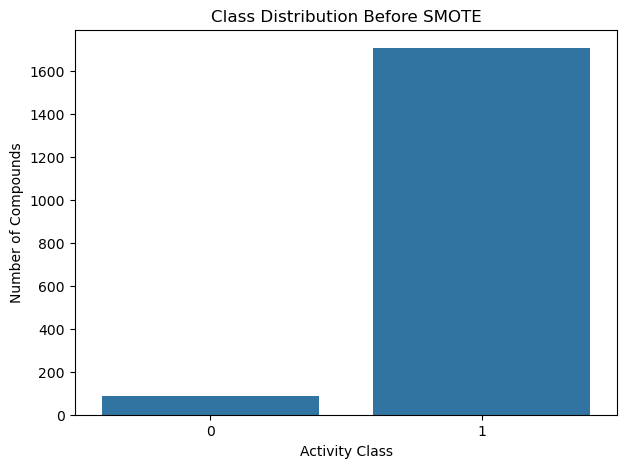

In [69]:
# Class distribution before SMOTE

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.xlabel("Activity Class")
plt.ylabel("Number of Compounds")
plt.title("Class Distribution Before SMOTE")

plt.show()

In [70]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Active compound
1    1705
0      88
Name: count, dtype: int64

After SMOTE:
Active compound
1    1705
0    1705
Name: count, dtype: int64


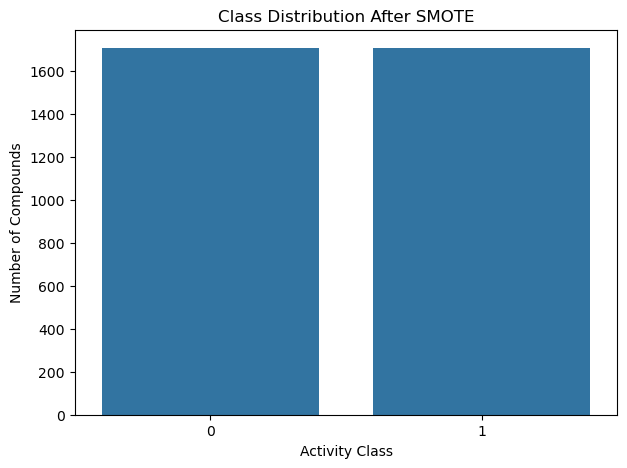

In [71]:
# Class distribution after SMOTE

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train_smote)

plt.xlabel("Activity Class")
plt.ylabel("Number of Compounds")
plt.title("Class Distribution After SMOTE")

plt.show()

# logistic regression 

In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [74]:
scaler = StandardScaler()

X_train_sm = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

LR = LogisticRegression(max_iter=1000)

LR.fit(X_train_sm, y_train_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [75]:
LR_predict = LR.predict(X_test_scaled)

In [76]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy_score =", accuracy_score(y_test, LR_predict))

print(classification_report(
    y_test,
    LR_predict,
    target_names=["Inactive", "Active"],
    digits=4
))

Accuracy_score = 0.9354120267260579
              precision    recall  f1-score   support

    Inactive     0.3704    0.4545    0.4082        22
      Active     0.9716    0.9602    0.9658       427

    accuracy                         0.9354       449
   macro avg     0.6710    0.7074    0.6870       449
weighted avg     0.9421    0.9354    0.9385       449



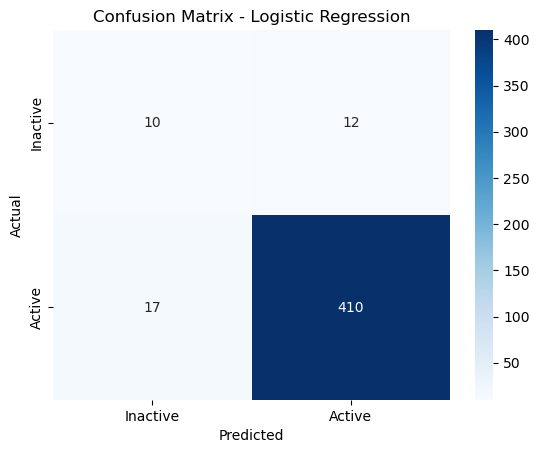

In [77]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, LR_predict)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

LR ROC AUC = 0.811


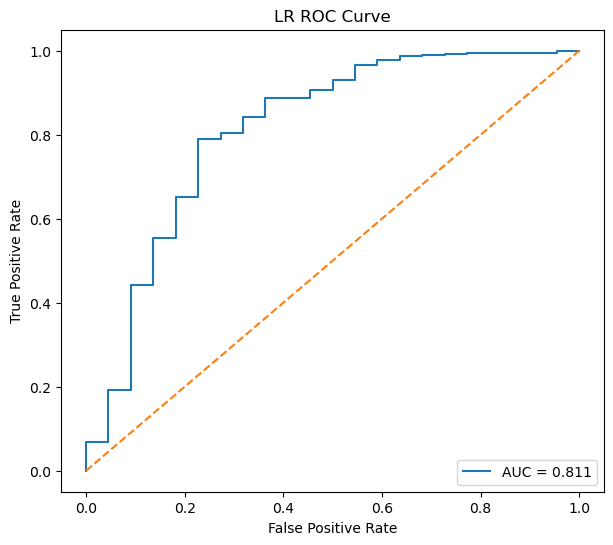

In [78]:
from sklearn.metrics import roc_curve, auc

LR_prob = LR.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, threshold = roc_curve(
    y_test,
    LR_prob,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % roc_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LR ROC Curve")

plt.legend(loc="lower right")

print("LR ROC AUC = %.3f" % roc_auc)

plt.show()

# decision tree 

In [79]:
from sklearn.tree import DecisionTreeClassifier

In [80]:
DT = DecisionTreeClassifier(
    random_state=42
)

DT.fit(
    X_train_smote,
    y_train_smote
)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [81]:
DT_predict = DT.predict(X_test)

In [82]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy_score =", accuracy_score(y_test, DT_predict))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        DT_predict,
        target_names=["Inactive", "Active"],
        digits=4
    )
)

Accuracy_score = 0.9376391982182628

Classification Report:
              precision    recall  f1-score   support

    Inactive     0.3636    0.3636    0.3636        22
      Active     0.9672    0.9672    0.9672       427

    accuracy                         0.9376       449
   macro avg     0.6654    0.6654    0.6654       449
weighted avg     0.9376    0.9376    0.9376       449



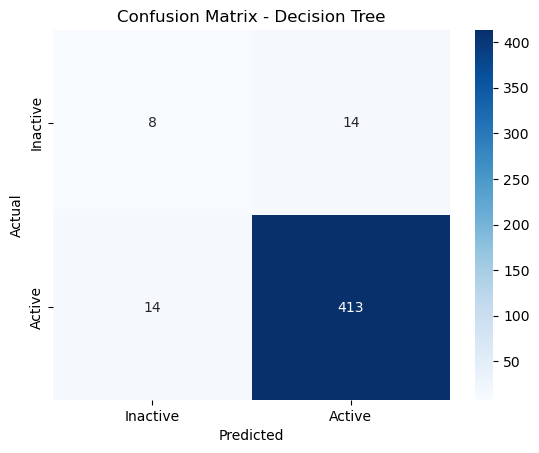

In [83]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    DT_predict
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")

plt.show()

Decision Tree ROC AUC = 0.665


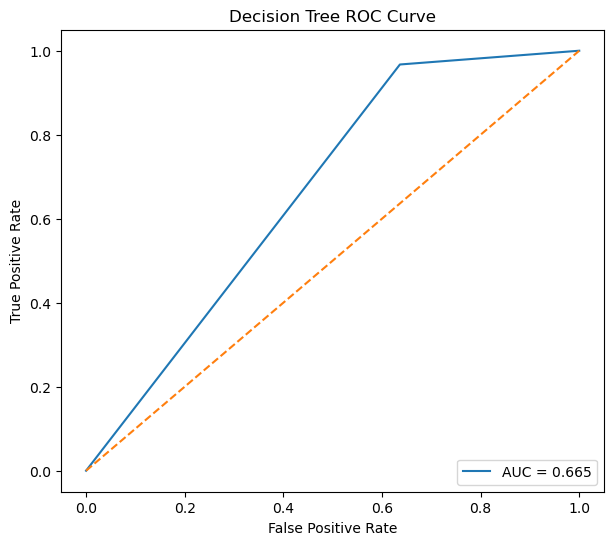

In [84]:
from sklearn.metrics import roc_curve, auc

DT_prob = DT.predict_proba(X_test)[:, 1]

fpr, tpr, threshold = roc_curve(
    y_test,
    DT_prob,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % roc_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")

plt.legend(loc="lower right")

print("Decision Tree ROC AUC = %.3f" % roc_auc)

plt.show()

# random forest

In [85]:
from sklearn.ensemble import RandomForestClassifier

In [86]:
RF = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

RF.fit(
    X_train_smote,
    y_train_smote
)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [87]:
RF_predict = RF.predict(X_test)

In [88]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy_score =", accuracy_score(y_test, RF_predict))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        RF_predict,
        target_names=["Inactive", "Active"],
        digits=4
    )
)

Accuracy_score = 0.9599109131403119

Classification Report:
              precision    recall  f1-score   support

    Inactive     0.7000    0.3182    0.4375        22
      Active     0.9658    0.9930    0.9792       427

    accuracy                         0.9599       449
   macro avg     0.8329    0.6556    0.7084       449
weighted avg     0.9528    0.9599    0.9527       449



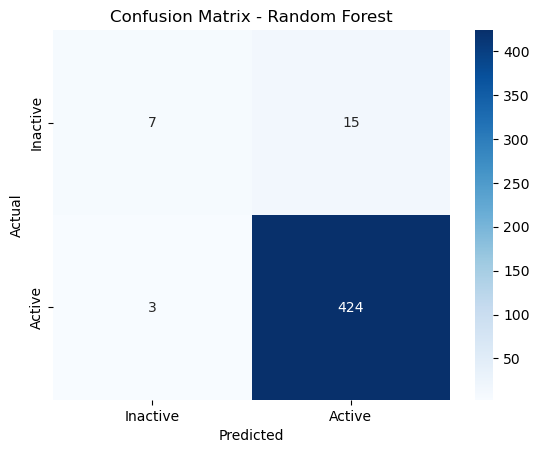

In [89]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    RF_predict
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")

plt.show()

Random Forest ROC AUC = 0.869


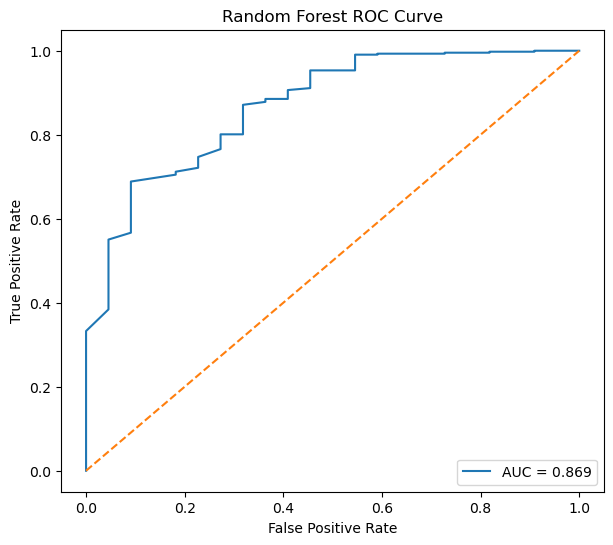

In [90]:
from sklearn.metrics import roc_curve, auc

RF_prob = RF.predict_proba(X_test)[:, 1]

fpr, tpr, threshold = roc_curve(
    y_test,
    RF_prob,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % roc_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")

plt.legend(loc="lower right")

print("Random Forest ROC AUC = %.3f" % roc_auc)

plt.show()

# XGBOOST

In [91]:
from xgboost import XGBClassifier

In [92]:
XGB = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

XGB.fit(
    X_train_smote,
    y_train_smote
)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [93]:
XGB_predict = XGB.predict(X_test)

In [94]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy_score =", accuracy_score(y_test, XGB_predict))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        XGB_predict,
        target_names=["Inactive", "Active"],
        digits=4
    )
)

Accuracy_score = 0.9465478841870824

Classification Report:
              precision    recall  f1-score   support

    Inactive     0.4286    0.2727    0.3333        22
      Active     0.9632    0.9813    0.9722       427

    accuracy                         0.9465       449
   macro avg     0.6959    0.6270    0.6527       449
weighted avg     0.9370    0.9465    0.9409       449



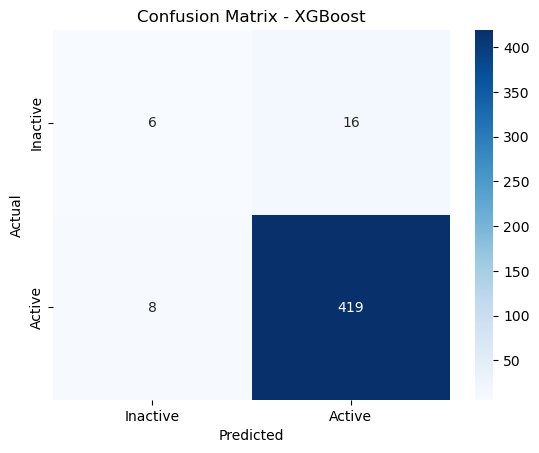

In [95]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    XGB_predict
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")

plt.show()

XGBoost ROC AUC = 0.835


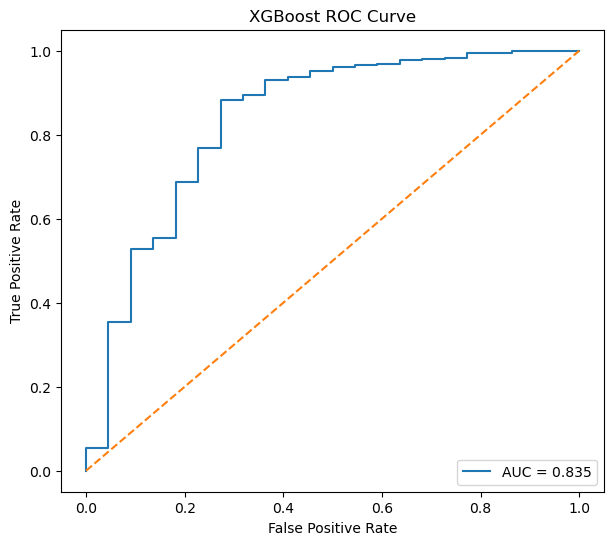

In [96]:
from sklearn.metrics import roc_curve, auc

XGB_prob = XGB.predict_proba(X_test)[:, 1]

fpr, tpr, threshold = roc_curve(
    y_test,
    XGB_prob,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % roc_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")

plt.legend(loc="lower right")

print("XGBoost ROC AUC = %.3f" % roc_auc)

plt.show()

# support vector machine

In [103]:
from sklearn.svm import SVC

In [104]:
SVM = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

SVM.fit(
    X_train_sm,
    y_train_smote
)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [105]:
SVM_predict = SVM.predict(X_test_scaled)

In [106]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy_score =", accuracy_score(y_test, SVM_predict))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        SVM_predict,
        target_names=["Inactive", "Active"],
        digits=4
    )
)

Accuracy_score = 0.9532293986636972

Classification Report:
              precision    recall  f1-score   support

    Inactive     0.5714    0.1818    0.2759        22
      Active     0.9593    0.9930    0.9758       427

    accuracy                         0.9532       449
   macro avg     0.7654    0.5874    0.6258       449
weighted avg     0.9403    0.9532    0.9415       449



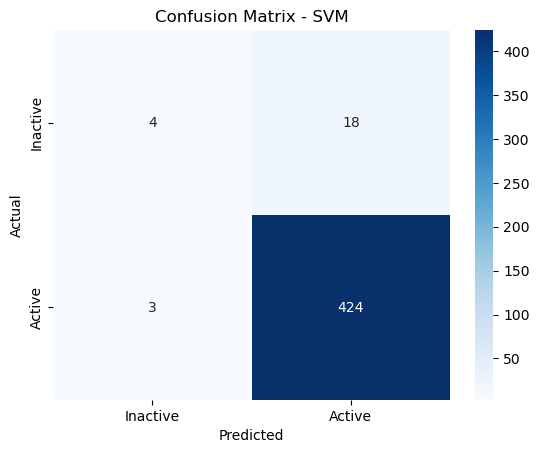

In [107]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    SVM_predict
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")

plt.show()

SVM ROC AUC = 0.754


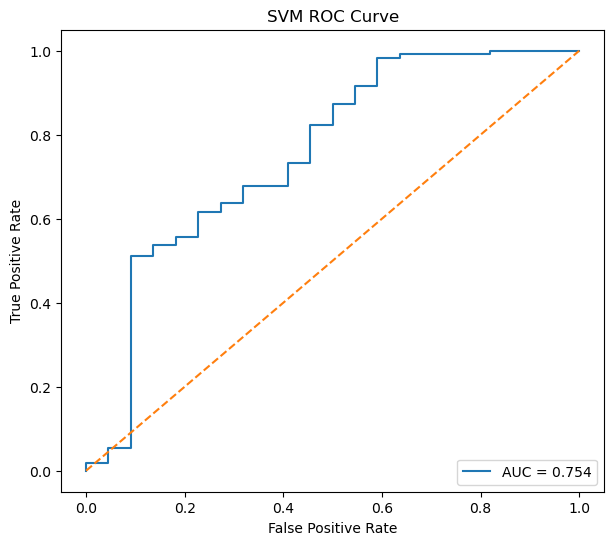

In [108]:
from sklearn.metrics import roc_curve, auc

SVM_prob = SVM.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, threshold = roc_curve(
    y_test,
    SVM_prob,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % roc_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curve")

plt.legend(loc="lower right")

print("SVM ROC AUC = %.3f" % roc_auc)

plt.show()

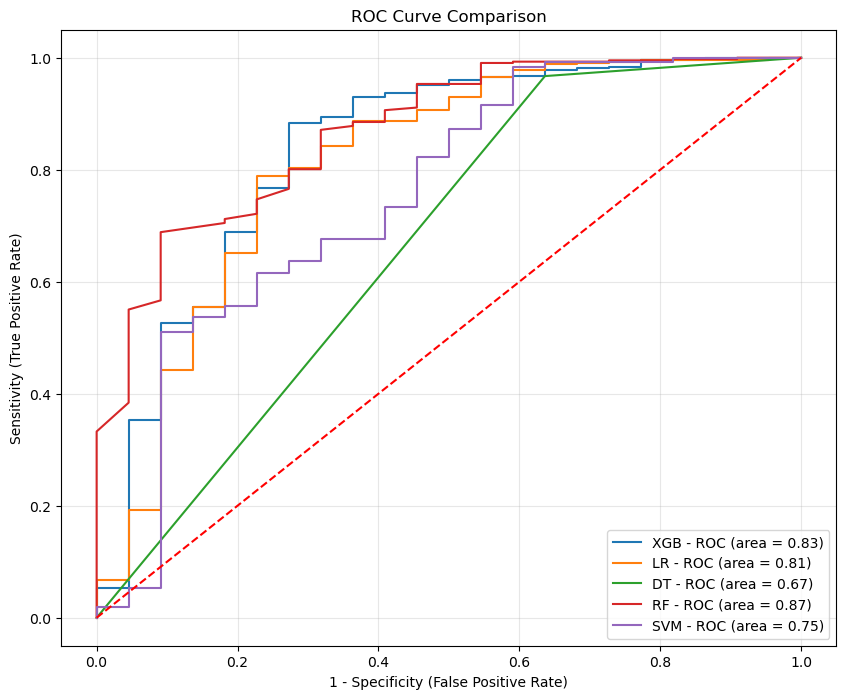

Logistic Regression AUC: 0.811
Decision Tree AUC: 0.665
Random Forest AUC: 0.869
XGBoost AUC: 0.835
SVM AUC: 0.754


In [109]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probability predictions for each model
LR_prob = LR.predict_proba(X_test_scaled)[:, 1]
DT_prob = DT.predict_proba(X_test)[:, 1]
RF_prob = RF.predict_proba(X_test)[:, 1]
XGB_prob = XGB.predict_proba(X_test)[:, 1]
SVM_prob = SVM.predict_proba(X_test_scaled)[:, 1]


# Calculate ROC curves
fpr_LR, tpr_LR, _ = roc_curve(y_test, LR_prob)
fpr_DT, tpr_DT, _ = roc_curve(y_test, DT_prob)
fpr_RF, tpr_RF, _ = roc_curve(y_test, RF_prob)
fpr_XGB, tpr_XGB, _ = roc_curve(y_test, XGB_prob)
fpr_SVM, tpr_SVM, _ = roc_curve(y_test, SVM_prob)


# Calculate AUC
auc_LR = auc(fpr_LR, tpr_LR)
auc_DT = auc(fpr_DT, tpr_DT)
auc_RF = auc(fpr_RF, tpr_RF)
auc_XGB = auc(fpr_XGB, tpr_XGB)
auc_SVM = auc(fpr_SVM, tpr_SVM)


# Plot ROC curves
plt.figure(figsize=(10, 8))

plt.plot(
    fpr_XGB, tpr_XGB,
    label="XGB - ROC (area = %.2f)" % auc_XGB
)

plt.plot(
    fpr_LR, tpr_LR,
    label="LR - ROC (area = %.2f)" % auc_LR
)

plt.plot(
    fpr_DT, tpr_DT,
    label="DT - ROC (area = %.2f)" % auc_DT
)

plt.plot(
    fpr_RF, tpr_RF,
    label="RF - ROC (area = %.2f)" % auc_RF
)

plt.plot(
    fpr_SVM, tpr_SVM,
    label="SVM - ROC (area = %.2f)" % auc_SVM
)


# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    "r--"
)


plt.xlabel("1 - Specificity (False Positive Rate)")
plt.ylabel("Sensitivity (True Positive Rate)")
plt.title("ROC Curve Comparison")

plt.legend(loc="lower right")

plt.grid(True, alpha=0.3)

plt.show()


# Print AUC values
print("Logistic Regression AUC:", round(auc_LR, 3))
print("Decision Tree AUC:", round(auc_DT, 3))
print("Random Forest AUC:", round(auc_RF, 3))
print("XGBoost AUC:", round(auc_XGB, 3))
print("SVM AUC:", round(auc_SVM, 3))

# rfecv value 

In [111]:
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# SMOTE + Random Forest
rfecv_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("rf", rf_model)
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# RFECV
rfecv = RFECV(
    estimator=rfecv_pipeline,
    step=50,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    min_features_to_select=10,
    importance_getter="named_steps.rf.feature_importances_"
)

# Run RFECV ONLY on training data
rfecv.fit(X_train, y_train)

print("Optimal number of features:", rfecv.n_features_)

Optimal number of features: 1322


In [112]:
selected_features = X_train.columns[rfecv.support_]

print("Number of selected features:", len(selected_features))

print("\nSelected features:")
print(selected_features.tolist())

Number of selected features: 1322

Selected features:
['MolWt', 'LogP', 'H_Donors', 'H_Acceptors', 'NumRotatableBonds', 'NumHeteroatoms', 'NumNitrogens', 'NumOxygens', 'NumHalogens', 'NumDoubleBonds', 'NumTripleBonds', 'NumRings', 'NumAromaticRings', 'NumAliphaticRings', 'NumAliphaticAtoms', 'FractionCSP3', 'morgan_0', 'morgan_1', 'morgan_2', 'morgan_3', 'morgan_4', 'morgan_5', 'morgan_6', 'morgan_7', 'morgan_8', 'morgan_9', 'morgan_10', 'morgan_11', 'morgan_12', 'morgan_13', 'morgan_14', 'morgan_15', 'morgan_16', 'morgan_18', 'morgan_19', 'morgan_20', 'morgan_21', 'morgan_22', 'morgan_23', 'morgan_24', 'morgan_25', 'morgan_26', 'morgan_27', 'morgan_28', 'morgan_29', 'morgan_30', 'morgan_31', 'morgan_32', 'morgan_33', 'morgan_34', 'morgan_36', 'morgan_37', 'morgan_38', 'morgan_39', 'morgan_40', 'morgan_41', 'morgan_42', 'morgan_43', 'morgan_44', 'morgan_45', 'morgan_46', 'morgan_47', 'morgan_48', 'morgan_49', 'morgan_50', 'morgan_51', 'morgan_52', 'morgan_53', 'morgan_54', 'morgan_55',

In [113]:
X_train_rfecv = X_train[selected_features]
X_test_rfecv = X_test[selected_features]

print("Original number of features:", X_train.shape[1])
print("RFECV selected features:", X_train_rfecv.shape[1])

print("X_train RFECV shape:", X_train_rfecv.shape)
print("X_test RFECV shape:", X_test_rfecv.shape)

Original number of features: 1872
RFECV selected features: 1322
X_train RFECV shape: (1793, 1322)
X_test RFECV shape: (449, 1322)


In [114]:
from imblearn.over_sampling import SMOTE

smote_rfecv = SMOTE(random_state=42)

X_train_rfecv_smote, y_train_rfecv_smote = smote_rfecv.fit_resample(
    X_train_rfecv,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_rfecv_smote.value_counts())

Before SMOTE:
Active compound
1    1705
0      88
Name: count, dtype: int64

After SMOTE:
Active compound
1    1705
0    1705
Name: count, dtype: int64


In [115]:
from sklearn.ensemble import RandomForestClassifier

RF_RFECV = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

RF_RFECV.fit(
    X_train_rfecv_smote,
    y_train_rfecv_smote
)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [117]:
RF_RFECV_predict = RF_RFECV.predict(X_test_rfecv)

In [118]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy_score =", accuracy_score(y_test, RF_RFECV_predict))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        RF_RFECV_predict,
        target_names=["Inactive", "Active"],
        digits=4
    )
)

Accuracy_score = 0.9599109131403119

Classification Report:
              precision    recall  f1-score   support

    Inactive     0.7000    0.3182    0.4375        22
      Active     0.9658    0.9930    0.9792       427

    accuracy                         0.9599       449
   macro avg     0.8329    0.6556    0.7084       449
weighted avg     0.9528    0.9599    0.9527       449



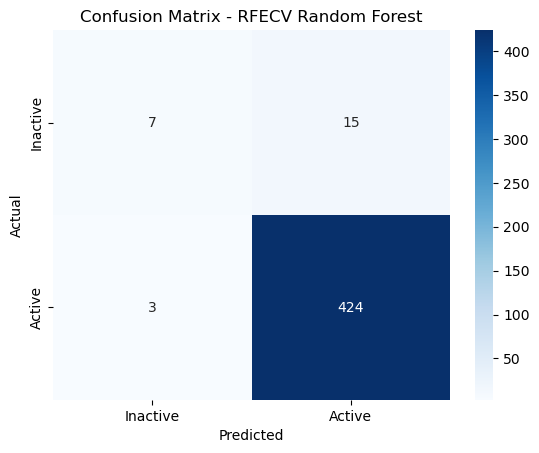

In [119]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    RF_RFECV_predict
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RFECV Random Forest")

plt.show()

RFECV Random Forest ROC AUC = 0.868


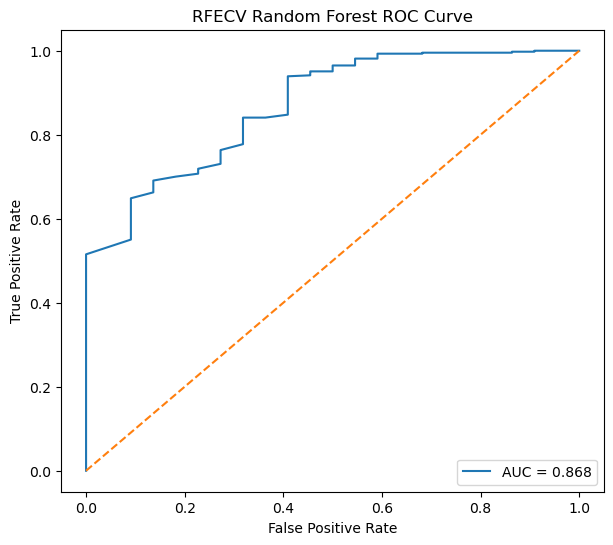

In [120]:
from sklearn.metrics import roc_curve, auc

RF_RFECV_prob = RF_RFECV.predict_proba(X_test_rfecv)[:, 1]

fpr, tpr, threshold = roc_curve(
    y_test,
    RF_RFECV_prob,
    pos_label=1
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % roc_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("RFECV Random Forest ROC Curve")

plt.legend(loc="lower right")

print("RFECV Random Forest ROC AUC = %.3f" % roc_auc)

plt.show()

In [121]:
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("Selected training features:", X_train_selected.shape)
print("Selected test features:", X_test_selected.shape)

Selected training features: (1793, 1322)
Selected test features: (449, 1322)


# hyperparameter tunning

In [128]:
import optuna

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [129]:
def objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators", 50, 500
    )

    max_depth = trial.suggest_int(
        "max_depth", 2, 50
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split", 2, 10
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf", 1, 5
    )

    max_features = trial.suggest_categorical(
        "max_features",
        ["sqrt", "log2"]
    )

    model = Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("rf", RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=42,
            n_jobs=-1
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train_selected,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    return scores.mean()

In [130]:
study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)

[I 2026-08-24 20:24:43,186] A new study created in memory with name: no-name-fdc9e219-9e7c-4461-8e34-5d6dd12bcd8f
[I 2026-08-24 20:24:45,994] Trial 0 finished with value: 0.8613698656393154 and parameters: {'n_estimators': 470, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'log2'}. Best is trial 0 with value: 0.8613698656393154.
[I 2026-08-24 20:24:53,953] Trial 1 finished with value: 0.8995859927548733 and parameters: {'n_estimators': 203, 'max_depth': 35, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.8995859927548733.
[I 2026-08-24 20:25:03,588] Trial 2 finished with value: 0.8754940294788491 and parameters: {'n_estimators': 482, 'max_depth': 44, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 1 with value: 0.8995859927548733.
[I 2026-08-24 20:25:07,639] Trial 3 finished with value: 0.8668937956414238 and parameters: {'n_estimators': 406, 'max_depth': 7, 'mi

In [131]:
print("Best ROC-AUC:", study.best_value)

print("\nBest Parameters:")
print(study.best_params)

Best ROC-AUC: 0.9041371974009547

Best Parameters:
{'n_estimators': 283, 'max_depth': 40, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


# k fold validation

In [133]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

final_RF = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(
        n_estimators=283,
        max_depth=40,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

print("Final tuned Random Forest created.")

Final tuned Random Forest created.


In [134]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    final_RF,
    X_train_selected,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("5-Fold Cross-Validation ROC-AUC Scores:")
print(cv_scores)

print("\nMean ROC-AUC:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

5-Fold Cross-Validation ROC-AUC Scores:
[0.88245357 0.89002933 0.94183773 0.94652406 0.8598413 ]

Mean ROC-AUC: 0.9041371974009547
Standard Deviation: 0.03420326126043481


In [135]:
final_RF.fit(
    X_train_selected,
    y_train
)

print("Final tuned Random Forest trained successfully.")

Final tuned Random Forest trained successfully.


In [136]:
final_RF_predict = final_RF.predict(
    X_test_selected
)

In [137]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy =", accuracy_score(y_test, final_RF_predict))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        final_RF_predict,
        target_names=["Inactive", "Active"],
        digits=4
    )
)

Accuracy = 0.9576837416481069

Classification Report:
              precision    recall  f1-score   support

    Inactive     0.6667    0.2727    0.3871        22
      Active     0.9636    0.9930    0.9781       427

    accuracy                         0.9577       449
   macro avg     0.8152    0.6329    0.6826       449
weighted avg     0.9491    0.9577    0.9491       449



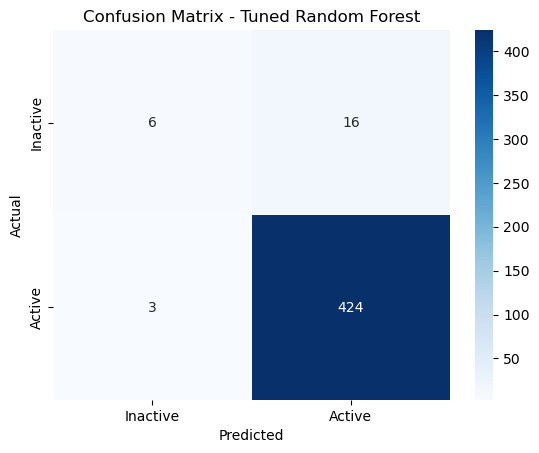

In [138]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    final_RF_predict
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Inactive", "Active"],
    yticklabels=["Inactive", "Active"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned Random Forest")

plt.show()

Final Test ROC-AUC = 0.8709


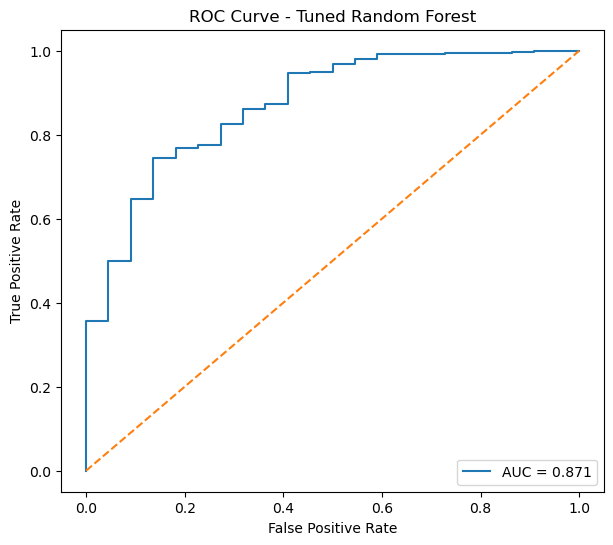

In [139]:
from sklearn.metrics import roc_curve, auc

final_RF_prob = final_RF.predict_proba(
    X_test_selected
)[:, 1]

fpr, tpr, _ = roc_curve(
    y_test,
    final_RF_prob
)

final_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label="AUC = %.3f" % final_auc
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest")

plt.legend(loc="lower right")

print("Final Test ROC-AUC =", round(final_auc, 4))

plt.show()

In [140]:
selected_features = X_train.columns[rfecv.support_]

selected_features_df = pd.DataFrame({
    "feature": selected_features
})

selected_features_df.to_csv(
    "rfecv_selected_features.csv",
    index=False
)

print("Selected features saved:", len(selected_features))

Selected features saved: 1322


In [141]:
import joblib

joblib.dump(
    final_RF,
    "final_tuned_RF.pkl"
)

print("Final tuned Random Forest saved.")

Final tuned Random Forest saved.


In [144]:
import pandas as pd

X_external_selected = pd.read_csv(
    r"C:\Users\sahan\external_selected_1322_features.csv"
)

print("External selected feature shape:", X_external_selected.shape)

External selected feature shape: (3639, 1322)


In [145]:
external_probability = final_RF.predict_proba(
    X_external_selected
)[:, 1]

print("Predictions generated:", len(external_probability))

Predictions generated: 3639


In [146]:
import pandas as pd

external_info = pd.read_csv(
    r"C:\Users\sahan\external_compound_info.csv"
)

print(external_info.shape)

(3639, 1)


In [147]:
external_results = external_info.copy()

external_results["Predicted_Active_Probability"] = external_probability

In [148]:
external_results = external_results.sort_values(
    "Predicted_Active_Probability",
    ascending=False
).reset_index(drop=True)

In [149]:
top20 = external_results.head(20).copy()

top20.insert(
    0,
    "Rank",
    range(1, 21)
)

print(top20)

    Rank  \
0      1   
1      2   
2      3   
3      4   
4      5   
5      6   
6      7   
7      8   
8      9   
9     10   
10    11   
11    12   
12    13   
13    14   
14    15   
15    16   
16    17   
17    18   
18    19   
19    20   

                                                                                     canonical_smiles  \
0                                     CNC(=O)c1ccc(N2C(=S)N(c3cnc(C#N)c(C(F)(F)F)c3)C(=O)C23CCC3)cc1F   
1                                     CNC(=O)c1ccc(N2C(=S)N(c3cnc(C#N)c(C(F)(F)F)c3)C(=O)C23CCC3)cc1F   
2                                      CNC(=O)c1ccc(N2C(=S)N(c3ccc(C#N)c(C(F)(F)F)c3)C(=O)C2(C)C)cc1F   
3                                      CNC(=O)c1ccc(N2C(=S)N(c3ccc(C#N)c(C(F)(F)F)c3)C(=O)C2(C)C)cc1F   
4   C[C@]12CCC(=O)C=C1[C@@H]1C[C@@H]1[C@H]1[C@@H]3[C@@H]4C[C@@H]4[C@@]4(CCC(=O)O4)[C@@]3(C)CC[C@@H]12   
5                                       C[C@]12CC[C@H]3[C@@H](CCC4=CC(=O)CC[C@@H]43)[C@@H]1CC[C@@H]2O   
6           

In [150]:
top20.to_csv(
    r"C:\Users\sahan\Top20_external_hits.csv",
    index=False
)

print("Top 20 CSV saved successfully.")

Top 20 CSV saved successfully.


In [151]:
import pandas as pd

prediction_df = pd.DataFrame({
    "Predicted_Active_Probability": external_probability
})

prediction_df.to_csv(
    r"C:\Users\sahan\external_predictions.csv",
    index=False
)

print("Predictions saved:", prediction_df.shape)

Predictions saved: (3639, 1)
